## Train Machine Learning Models

In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv("college_student_placement_dataset.csv")

# Copy dataset
df_ml = df.copy()

# Drop College_ID
df_ml.drop("College_ID", axis=1, inplace=True)

# Convert categorical values
df_ml["Internship_Experience"] = df_ml["Internship_Experience"].map({
    "No": 0,
    "Yes": 1
})

df_ml["Placement"] = df_ml["Placement"].map({
    "No": 0,
    "Yes": 1
})

# Separate features and target
X = df_ml.drop("Placement", axis=1)
y = df_ml["Placement"]

# Train-test split
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Scaling
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Setup completed!")

Setup completed!


### Logistic Regression

In [12]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

lr_model = LogisticRegression(max_iter=1000)

lr_model.fit(X_train_scaled, y_train)

y_pred_lr = lr_model.predict(X_test_scaled)

print("Logistic Regression Accuracy:",
      accuracy_score(y_test, y_pred_lr))

Logistic Regression Accuracy: 0.9035


### Decision Tree Classifier

In [13]:
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(
    random_state=42,
    class_weight="balanced"
)

dt_model.fit(X_train, y_train)

y_pred_dt = dt_model.predict(X_test)

print("Decision Tree Accuracy:",
      accuracy_score(y_test, y_pred_dt))

Decision Tree Accuracy: 1.0


### Random Forest Classifier

In [14]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced"
)

rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)

print("Random Forest Accuracy:",
      accuracy_score(y_test, y_pred_rf))

Random Forest Accuracy: 1.0


### model Comparsion

In [15]:
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_dt),
        accuracy_score(y_test, y_pred_rf)
    ]
})

results["Accuracy (%)"] = results["Accuracy"] * 100

results

,Model,Accuracy,Accuracy (%)
0,Logistic Regression,0.9035,90.35
1,Decision Tree,1.0000,100.00
2,Random Forest,1.0000,100.00


#### Accuracy Comparison Graph

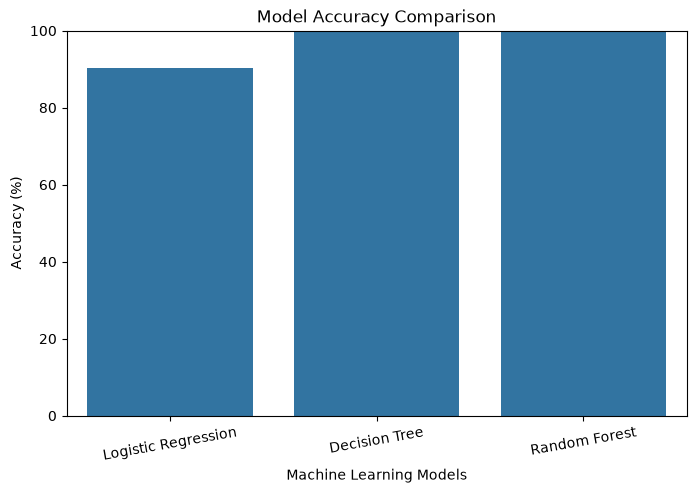

In [16]:
plt.figure(figsize=(8,5))

sns.barplot(
    x="Model",
    y="Accuracy (%)",
    data=results
)

plt.title("Model Accuracy Comparison")
plt.xlabel("Machine Learning Models")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)

plt.xticks(rotation=10)
plt.show()

In [17]:
best_model = results.loc[results["Accuracy"].idxmax()]

print("Best Model:", best_model["Model"])
print("Best Accuracy:", round(best_model["Accuracy (%)"], 2), "%")

Best Model: Decision Tree
Best Accuracy: 100.0 %


### Confusion Matrix

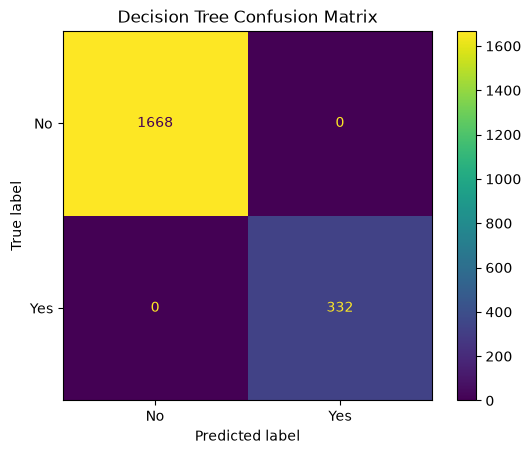

In [18]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred_dt)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No", "Yes"]
)

disp.plot()

plt.title("Decision Tree Confusion Matrix")
plt.show()

In [19]:
print(classification_report(y_test, y_pred_dt))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1668
           1       1.00      1.00      1.00       332

    accuracy                           1.00      2000
   macro avg       1.00      1.00      1.00      2000
weighted avg       1.00      1.00      1.00      2000



#### “Among the tested models, Decision Tree achieved the highest accuracy of 100% and was selected as the best model based on the accuracy comparison.”

In [20]:
# Feature importance


feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": dt_model.feature_importances_
})

# Sort values
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance)

                  Feature    Importance
0                      IQ  4.016466e-01
6    Communication_Skills  2.582265e-01
2                    CGPA  2.359924e-01
7      Projects_Completed  1.041344e-01
5  Extra_Curricular_Score  1.288673e-15
1         Prev_Sem_Result  7.308899e-16
4   Internship_Experience  4.230058e-16
3    Academic_Performance  5.784873e-17


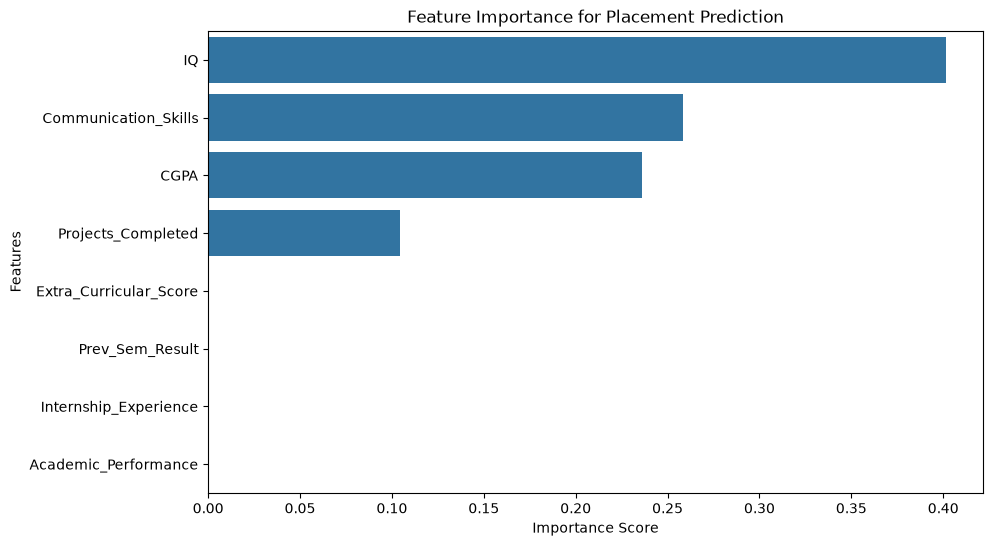

In [21]:
plt.figure(figsize=(10,6))

sns.barplot(
    x="Importance",
    y="Feature",
    data=feature_importance
)

plt.title("Feature Importance for Placement Prediction")
plt.xlabel("Importance Score")
plt.ylabel("Features")

plt.show()

#### “The feature importance analysis identifies which student-related factors contribute most to placement prediction.”

In [22]:
# Example new student data


new_student = pd.DataFrame({
    "IQ": [120],
    "Prev_Sem_Result": [75],
    "CGPA": [8.5],
    "Academic_Performance": [85],
    "Internship_Experience": [1],
    "Extra_Curricular_Score": [70],
    "Communication_Skills": [8],
    "Projects_Completed": [3]
})

# Predict placement

prediction = dt_model.predict(new_student)

if prediction[0] == 1:
    print("Prediction: Student is likely to be PLACED ✅")
else:
    print("Prediction: Student is likely to be NOT PLACED ❌")

Prediction: Student is likely to be PLACED ✅


In [23]:
import joblib

joblib.dump(dt_model, "placement_model.pkl")

print("Model saved successfully!")

Model saved successfully!
